In [2]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import numpy as np
import os
import shutil

In [7]:
# Ensure balanced dataset with exactly 1400 training and 380 test images per class
def balance_dataset(source_dir, dest_dir, num_samples):
    if not os.path.exists(dest_dir):
        os.makedirs(dest_dir)
    
    for class_name in os.listdir(source_dir):
        class_path = os.path.join(source_dir, class_name)
        dest_class_path = os.path.join(dest_dir, class_name)
        os.makedirs(dest_class_path, exist_ok=True)
        
        images = os.listdir(class_path)
        selected_images = np.random.choice(images, num_samples, replace=False)
        
        for img in selected_images:
            shutil.copy(os.path.join(class_path, img), os.path.join(dest_class_path, img))

# Create balanced dataset
balance_dataset(train_dir, balanced_train_dir, 1400)
balance_dataset(test_dir, balanced_test_dir, 380)

In [8]:
# Image parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Data Augmentation & Preprocessing
datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.efficientnet.preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

# Load dataset
train_generator = datagen.flow_from_directory(
    balanced_train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_generator = datagen.flow_from_directory(
    balanced_test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)


Found 8400 images belonging to 6 classes.
Found 2280 images belonging to 6 classes.


In [9]:
# Load EfficientNetB0 as base model
base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze initial layers

# Custom classification head
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.5)(x)
output = Dense(6, activation='softmax')(x)  # 6 classes

model = Model(inputs=base_model.input, outputs=output)

# Compile model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
checkpoint = ModelCheckpoint("efficientnet_best.h5", save_best_only=True, monitor='val_accuracy', mode='max')
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 17s 1us/step


In [10]:
# Train model
history = model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=20,
    callbacks=[checkpoint, early_stopping]
)

# Save final model
model.save("efficientnet_fruit_classifier.h5")

c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3800 - loss: 1.5453

263/263 ━━━━━━━━━━━━━━━━━━━━ 565s 2s/step - accuracy: 0.3807 - loss: 1.5441 - val_accuracy: 0.8715 - val_loss: 0.7252
Epoch 2/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8176 - loss: 0.7113

263/263 ━━━━━━━━━━━━━━━━━━━━ 389s 1s/step - accuracy: 0.8177 - loss: 0.7110 - val_accuracy: 0.9224 - val_loss: 0.4297
Epoch 3/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8944 - loss: 0.4625

263/263 ━━━━━━━━━━━━━━━━━━━━ 392s 1s/step - accuracy: 0.8944 - loss: 0.4624 - val_accuracy: 0.9408 - val_loss: 0.3067
Epoch 4/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9167 - loss: 0.3634

263/263 ━━━━━━━━━━━━━━━━━━━━ 389s 1s/step - accuracy: 0.9167 - loss: 0.3633 - val_accuracy: 0.9478 - val_loss: 0.2504
Epoch 5/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9299 - loss: 0.2893

... (5 outputs left out)

263/263 ━━━━━━━━━━━━━━━━━━━━ 268s 1s/step - accuracy: 0.9624 - loss: 0.1410 - val_accuracy: 0.9754 - val_loss: 0.1029
Epoch 14/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 271s 1s/step - accuracy: 0.9636 - loss: 0.1347 - val_accuracy: 0.9684 - val_loss: 0.1033
Epoch 15/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 816ms/step - accuracy: 0.9626 - loss: 0.1285

263/263 ━━━━━━━━━━━━━━━━━━━━ 272s 1s/step - accuracy: 0.9626 - loss: 0.1285 - val_accuracy: 0.9789 - val_loss: 0.0935
Epoch 16/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 271s 1s/step - accuracy: 0.9683 - loss: 0.1161 - val_accuracy: 0.9789 - val_loss: 0.0859
Epoch 17/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 270s 1s/step - accuracy: 0.9676 - loss: 0.1172 - val_accuracy: 0.9781 - val_loss: 0.0870
Epoch 18/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 806ms/step - accuracy: 0.9714 - loss: 0.1141

263/263 ━━━━━━━━━━━━━━━━━━━━ 269s 1s/step - accuracy: 0.9714 - loss: 0.1141 - val_accuracy: 0.9798 - val_loss: 0.0823
Epoch 19/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 812ms/step - accuracy: 0.9747 - loss: 0.1029

263/263 ━━━━━━━━━━━━━━━━━━━━ 271s 1s/step - accuracy: 0.9747 - loss: 0.1029 - val_accuracy: 0.9842 - val_loss: 0.0764
Epoch 20/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 272s 1s/step - accuracy: 0.9738 - loss: 0.1042 - val_accuracy: 0.9842 - val_loss: 0.0739


In [14]:
model = tf.keras.models.load_model("efficientnet_fruit_classifier.h5")
print(model.history)  # This might be None if not saved


AttributeError: 'Functional' object has no attribute 'history'

Found 2280 files belonging to 6 classes.
72/72 ━━━━━━━━━━━━━━━━━━━━ 70s 945ms/step
Confusion Matrix:
[[376   0   0   4   0   0]
 [  0 380   0   0   0   0]
 [  1   0 376   2   0   1]
 [ 11   0   0 363   0   6]
 [  0   1   0   0 379   0]
 [  0   0   3   5   0 372]]


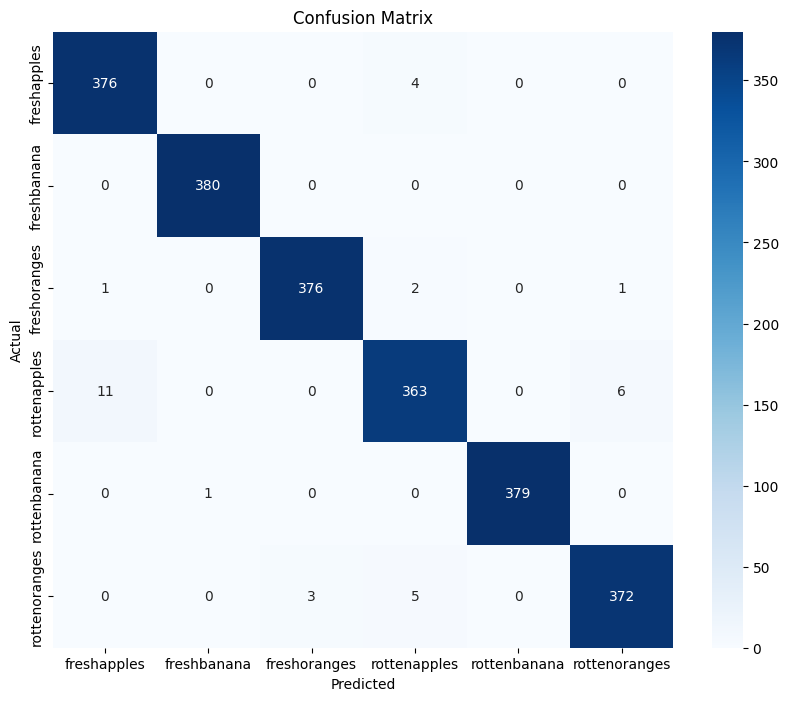


Classification Report:
               precision    recall  f1-score   support

  freshapples       0.97      0.99      0.98       380
  freshbanana       1.00      1.00      1.00       380
 freshoranges       0.99      0.99      0.99       380
 rottenapples       0.97      0.96      0.96       380
 rottenbanana       1.00      1.00      1.00       380
rottenoranges       0.98      0.98      0.98       380

     accuracy                           0.99      2280
    macro avg       0.99      0.99      0.99      2280
 weighted avg       0.99      0.99      0.99      2280



In [1]:
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load the trained model
model = tf.keras.models.load_model("efficientnet_fruit_classifier.h5")

# Step 2: Load the test data
test_data = tf.keras.preprocessing.image_dataset_from_directory(
    "dataset/test",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False  # Important: Keep order to match labels
)

# Step 3: Get class names
class_names = test_data.class_names

# Step 4: Predict on the test data
y_true = np.concatenate([y for x, y in test_data], axis=0)
y_pred_probs = model.predict(test_data)
y_pred = np.argmax(y_pred_probs, axis=1)

# Step 5: Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(cm)

# Step 6: Display confusion matrix as heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Optional: Print classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


In [12]:
# Plot Training & Validation Accuracy and Loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training & Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training & Validation Loss')

plt.show()

NameError: name 'plt' is not defined

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


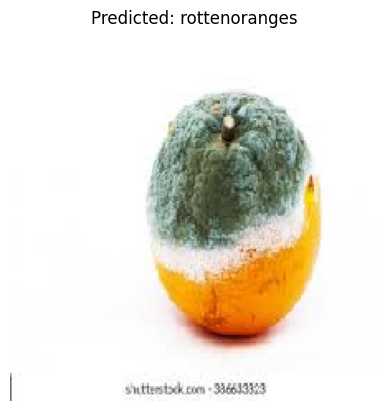

Predicted Class: rottenoranges


In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Define image size and class labels
IMG_SIZE = (224, 224)
CLASS_NAMES = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Load trained model
MODEL_PATH = "efficientnet_fruit_classifier.h5"
model = tf.keras.models.load_model(MODEL_PATH)

# Function to classify an image
def classify_image(image_path):
    # Load and preprocess image
    img = load_img(image_path, target_size=IMG_SIZE)
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)

    # Predict class
    predictions = model.predict(img_array)
    class_index = np.argmax(predictions)  # Get the index of the highest probability
    class_label = CLASS_NAMES[class_index]

    # Display image with prediction
    plt.imshow(img)
    plt.title(f"Predicted: {class_label}")
    plt.axis("off")
    plt.show()

    return class_label

# Example usage
image_path = "dataset/download 20.jpeg"  
predicted_class = classify_image(image_path)
print(f"Predicted Class: {predicted_class}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step


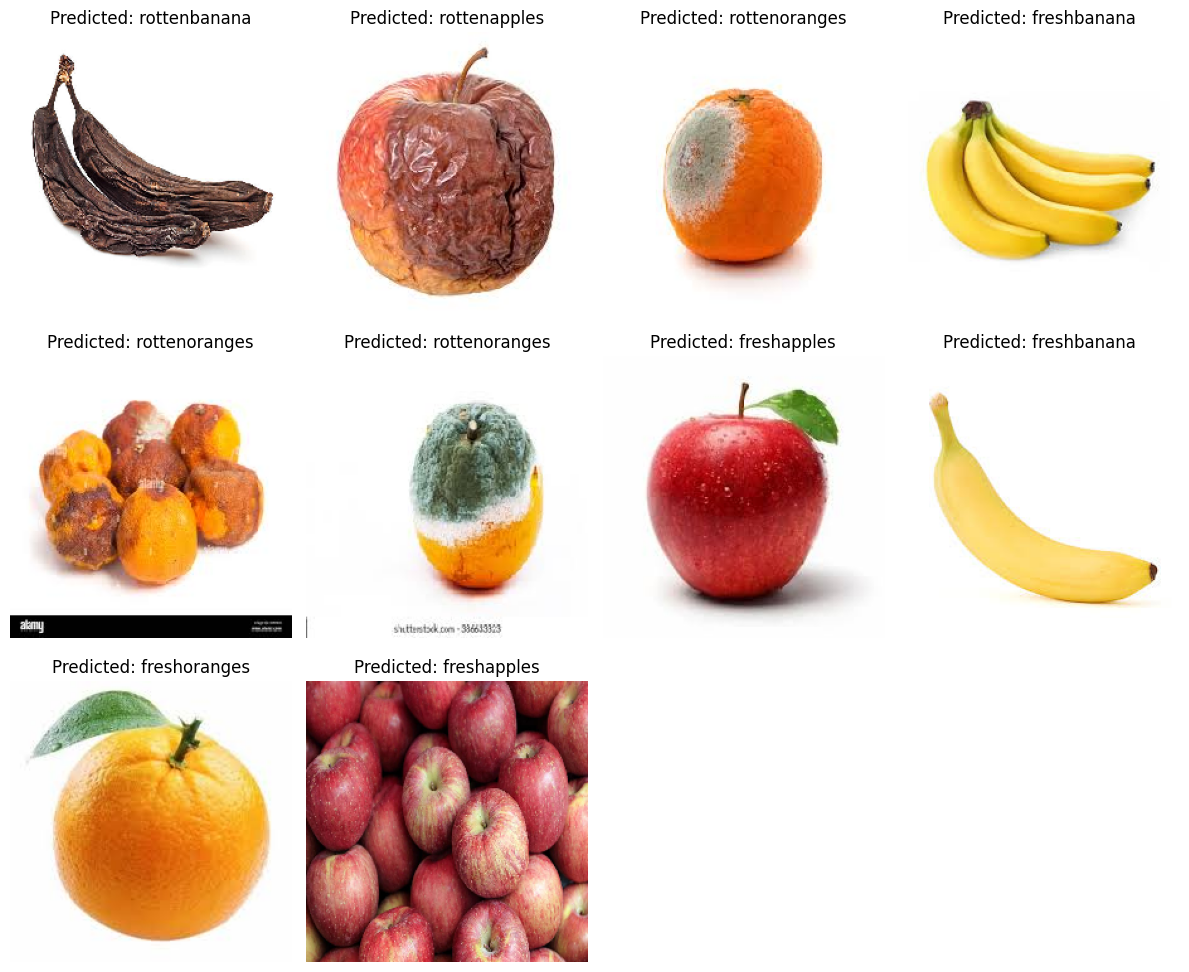

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt
import os

# Load trained model
model_path = "efficientnet_fruit_classifier.h5"
model = load_model(model_path)

# Define image paths 
image_dir = "./dataset/"
image_files = [
    "banana rotten.jpg",
    "download (1).jpeg",
    "download (4).jpeg",
    "download (5).jpg",
    "download 10.jpeg",
    "download 20.jpeg",
    "fresh apple.jpeg",
    "fresh banana.jpeg",
    "fresh orange.jpeg",
    "image 1.jpg"
]

image_paths = [os.path.join(image_dir, img) for img in image_files]

# Class labels
class_names = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Image size
IMG_SIZE = (224, 224)

# Function to classify images
def classify_images(image_paths, model):
    plt.figure(figsize=(12, 10))
    
    for i, img_path in enumerate(image_paths):
        # Load and preprocess image
        img = load_img(img_path, target_size=IMG_SIZE)
        img_array = img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)

        # Predict
        predictions = model.predict(img_array)
        class_index = np.argmax(predictions)
        class_label = class_names[class_index]

        # Plot image with prediction
        plt.subplot(3, 4, i+1) 
        plt.imshow(img)
        plt.title(f"Predicted: {class_label}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# Run prediction
classify_images(image_paths, model)


In [ ]:
from tensorflow.keras.models import load_model

model = load_model("efficientnet_fruit_classifier.h5")  # or your own .h5 file path


In [1]:
import shap
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import numpy as np
import os
from tensorflow.keras.models import load_model

# Load the EfficientNet model
model_path = "efficientnet_fruit_classifier.h5"
model = load_model(model_path)

# Path to your test data
image_dir = "./dataset/"
image_files = [
    "banana rotten.jpg", "download (1).jpeg", "download (4).jpeg", "download (5).jpg",
    "download 10.jpeg", "download 20.jpeg", "fresh apple.jpeg", "fresh banana.jpeg",
    "fresh orange.jpeg", "image 1.jpg"
]

# Preprocess the images for EfficientNet input
def preprocess_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))  # Resize to EfficientNet's input size
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)  # Preprocess for EfficientNet
    return img_array

# Process all test images
test_images = []
for img_file in image_files:
    img_path = os.path.join(image_dir, img_file)
    test_images.append(preprocess_image(img_path))

# Stack all images into a numpy array
test_images = np.vstack(test_images)

# Use the model to make predictions on the test images
predictions = model.predict(test_images)

# You can visualize the predictions or print them
print("Predictions: ", predictions)

# Now, use SHAP for explaining one image (choose the first image for example)
explainer = shap.DeepExplainer(model, test_images)  # Provide background data for the explainer (can use a subset)
shap_values = explainer.shap_values(test_images)

# Visualize the SHAP explanation for the first image
shap.initjs()
shap.image_plot(shap_values, test_images)


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Predictions:  [[5.3554697e-07 1.1791483e-04 5.3315802e-07 2.5208101e-05 9.9985361e-01
  2.2788299e-06]
 [9.1249976e-06 5.2250396e-08 2.5581894e-06 9.9991345e-01 1.2588714e-05
  6.2116531e-05]
 [5.5375596e-04 4.6422870e-06 9.5880534e-03 6.4650304e-03 4.4436720e-06
  9.8338401e-01]
 [1.3258963e-04 9.9887484e-01 3.5288531e-04 5.8188718e-05 4.1608707e-04
  1.6539931e-04]
 [3.3647775e-05 1.7832404e-05 2.5097134e-02 4.9720751e-03 5.5449676e-05
  9.6982390e-01]
 [3.7568666e-06 8.9587689e-07 3.1307370e-06 5.5124465e-04 4.4890621e-06
  9.9943644e-01]
 [9.6869421e-01 8.4944251e-05 4.2254589e-03 2.4529865e-02 4.4899549e-05
  2.4206687e-03]
 [2.5423130e-04 9.9462849e-01 1.7237152e-03 1.8051405e-04 2.9882980e-03
  2.2485248e-04]
 [9.4218217e-03 6.5135589e-04 9.7424024e-01 4.6410584e-03 7.5885335e-05
  1.0969682e-02]
 [8.6270708e-01 1.8114415e-04 5.0123548e-03 1.2222224e-01 1.5477615e-04
  9.7224126e-03]]


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\shap\explainers\_deep\deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\keras\src\models\functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(10, 224, 224, 3))']
  warnings.warn(msg)
c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\keras\src\models\functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(20, 224, 224, 3))']
  warnings.warn(msg)


StagingError: in user code:

    File "c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\shap\explainers\_deep\deep_tf.py", line 265, in grad_graph  *
        x_grad = tape.gradient(out, shap_rAnD)

    LookupError: gradient registry has no entry for: shap_DepthwiseConv2dNative


In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import os
import cv2

# Load the EfficientNet model
model_path = "efficientnet_fruit_classifier.h5"
model = load_model(model_path)

# Path to your test data
image_dir = "./dataset/"
image_files = [
    "banana rotten.jpg", "download (1).jpeg", "download (4).jpeg", "download (5).jpg",
    "download 10.jpeg", "download 20.jpeg", "fresh apple.jpeg", "fresh banana.jpeg",
    "fresh orange.jpeg", "image 1.jpg"
]

# Preprocess the image for EfficientNet input
def preprocess_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))  # Resize to EfficientNet's input size
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)  # Preprocess for EfficientNet
    return img_array

# Process a test image
img_file = image_files[0]  # For example, taking the first image
img_path = os.path.join(image_dir, img_file)
img = preprocess_image(img_path)

# Choose the final convolutional layer
last_conv_layer = model.get_layer('top_conv')  # This is the last conv layer in EfficientNet
# Get the model's prediction for the image
predictions = model.predict(img)
class_idx = np.argmax(predictions[0])  # Get the predicted class index

# Compute the gradient of the class output value w.r.t the final convolutional layer
with tf.GradientTape() as tape:
    # Watch the input image
    tape.watch(img)
    # Forward pass: Get the output of the model
    conv_output = last_conv_layer(img)
    model_output = model(img)

    # Get the class output (based on the predicted class)
    class_output = model_output[:, class_idx]

# Compute the gradient of class output with respect to the convolutional layer output
grads = tape.gradient(class_output, conv_output)

# Pool the gradients across all the filters (mean pooling)
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

# Multiply the pooled gradients with the convolutional output
conv_output = conv_output[0].numpy()
pooled_grads = pooled_grads.numpy()

for i in range(conv_output.shape[-1]):
    conv_output[:, :, i] *= pooled_grads[i]

# Create the heatmap by averaging the channels of the modified convolutional output
heatmap = np.mean(conv_output, axis=-1)

# Normalize the heatmap between 0 and 1
heatmap = np.maximum(heatmap, 0)
heatmap /= np.max(heatmap)

# Resize the heatmap to match the input image size
heatmap = cv2.resize(heatmap, (224, 224))

# Load the original image to overlay the heatmap
original_img = cv2.imread(img_path)
original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)

# Create an overlay image by combining the heatmap with the original image
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
superimposed_img = cv2.addWeighted(original_img, 0.6, heatmap, 0.4, 0)

# Display the original image and Grad-CAM result
plt.figure(figsize=(10, 10))
plt.subplot(1, 2, 1)
plt.imshow(original_img)
plt.title("Original Image")
plt.subplot(1, 2, 2)
plt.imshow(superimposed_img)
plt.title("Grad-CAM")
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


ValueError: Passed in object [[[[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]

  [[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]

  [[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]

  ...

  [[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]

  [[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]

  [[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]]] of type 'ndarray', not tf.Tensor or tf.Variable or ExtensionType.

In [4]:
pip install shap


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import shap
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import os

# Load your model
model = load_model("efficientnet_fruit_classifier.h5")

# Choose a few background images (used for SHAP baseline)
image_dir = "./dataset/"
background_files = ["fresh apple.jpeg", "fresh banana.jpeg", "fresh orange.jpeg"]
background_imgs = []

for file in background_files:
    img = image.load_img(os.path.join(image_dir, file), target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)
    background_imgs.append(img_array)

background = np.array(background_imgs)

# Select an image to explain
img_to_explain = image.load_img(os.path.join(image_dir, "banana rotten.jpg"), target_size=(224, 224))
img_array = image.img_to_array(img_to_explain)
img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Wrap the model with a SHAP explainer
explainer = shap.DeepExplainer(model, background)


# Compute SHAP values
shap_values = explainer.shap_values(img_array)

# Visualize SHAP values for each class
shap.image_plot(shap_values, img_array)


StagingError: in user code:

    File "c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\shap\explainers\_deep\deep_tf.py", line 265, in grad_graph  *
        x_grad = tape.gradient(out, shap_rAnD)

    LookupError: gradient registry has no entry for: shap_DepthwiseConv2dNative


In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image

# Load model
model = load_model("efficientnet_fruit_classifier.h5")

# Load image
img_path = 'path_to_image.jpg'  # Replace this
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Define masker
masker = shap.maskers.Image("inpaint_telea", img_array[0].shape)

# Define explainer using model.predict
explainer = shap.Explainer(model.predict, masker, output_names=["class_"+str(i) for i in range(1000)])

# Calculate SHAP values
shap_values = explainer(img_array)

# Plot
shap.image_plot(shap_values)


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import os
import cv2

# Load the EfficientNet model
model_path = "efficientnet_fruit_classifier.h5"
model = load_model(model_path)

# Path to your test data
image_dir = "./dataset/"
image_files = [
    "banana rotten.jpg", "download (1).jpeg", "download (4).jpeg", "download (5).jpg",
    "download 10.jpeg", "download 20.jpeg", "fresh apple.jpeg", "fresh banana.jpeg",
    "fresh orange.jpeg", "image 1.jpg"
]

# Preprocess the image for EfficientNet input
def preprocess_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))  # Resize to EfficientNet's input size
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)  # Preprocess for EfficientNet
    return img_array

# Process a test image
img_file = image_files[0]  # For example, taking the first image
img_path = os.path.join(image_dir, img_file)
img = preprocess_image(img_path)

# Convert img to TensorFlow tensor
img_tensor = tf.convert_to_tensor(img, dtype=tf.float32)

# Choose the final convolutional layer
last_conv_layer = model.get_layer('top_conv')  # This is the last conv layer in EfficientNet
# Get the model's prediction for the image
predictions = model.predict(img)
class_idx = np.argmax(predictions[0])  # Get the predicted class index

# Compute the gradient of the class output value w.r.t the final convolutional layer
with tf.GradientTape() as tape:
    # Watch the input image tensor
    tape.watch(img_tensor)
    # Forward pass: Get the output of the model
    conv_output = last_conv_layer(img_tensor)
    model_output = model(img_tensor)

    # Get the class output (based on the predicted class)
    class_output = model_output[:, class_idx]

# Compute the gradient of class output with respect to the convolutional layer output
grads = tape.gradient(class_output, conv_output)

# Pool the gradients across all the filters (mean pooling)
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

# Multiply the pooled gradients with the convolutional output
conv_output = conv_output[0].numpy()
pooled_grads = pooled_grads.numpy()

for i in range(conv_output.shape[-1]):
    conv_output[:, :, i] *= pooled_grads[i]

# Create the heatmap by averaging the channels of the modified convolutional output
heatmap = np.mean(conv_output, axis=-1)

# Normalize the heatmap between 0 and 1
heatmap = np.maximum(heatmap, 0)
heatmap /= np.max(heatmap)

# Resize the heatmap to match the input image size
heatmap = cv2.resize(heatmap, (224, 224))

# Load the original image to overlay the heatmap
original_img = cv2.imread(img_path)
original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)

# Create an overlay image by combining the heatmap with the original image
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
superimposed_img = cv2.addWeighted(original_img, 0.6, heatmap, 0.4, 0)


plt.figure(figsize=(10, 10))
plt.subplot(1, 2, 1)
plt.imshow(original_img)
plt.title("Original Image")
plt.subplot(1, 2, 2)
plt.imshow(superimposed_img)
plt.title("Grad-CAM")
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


ValueError: Input 0 of layer "top_conv" is incompatible with the layer: expected axis -1 of input shape to have value 320, but received input with shape (1, 224, 224, 3)